# Wikipedia Attention vs. Stock Price: Research-Before-Investing Signal

People often research a company on Wikipedia before (or while deciding whether to) buy its stock.
This notebook tests whether **Wikipedia pageview activity** for a company's article contains a
tradeable signal about its stock — either as a **leading indicator** (attention builds, then price
moves) or a **lagging/coincident indicator** (price moves on news, then people go look the company up).

This mirrors the prior `coinbaseResearch` notebook's approach (calendar alignment, rolling
correlation, lead-lag, Granger causality, event studies, toy backtest) applied to a different
alternative dataset: **Wikipedia pageviews** via the free Wikimedia REST API (no key required).

**Companies studied** (deliberately mixed retail-attention profiles):
- **TSLA** (Tesla) — famously retail/attention-driven
- **GME** (GameStop) — the canonical "meme stock," 2021 attention shock is a natural event study
- **COIN** (Coinbase) — retail crypto-adjacent, continuity with the companion notebook
- **AAPL** (Apple) — mega-cap control; attention is high but diffuse/steady, less "research before
  buying" behavior expected since it's a widely-known, low-information-asymmetry name

**Core hypotheses:**
1. Pageview spikes (abnormal attention) precede or coincide with abnormal stock returns/volatility.
2. The relationship is stronger for "meme"/retail names (GME, TSLA, COIN) than for a mega-cap
   control (AAPL) — i.e. attention-driven trading matters more where the investor base is more retail.
3. Weekend/overnight pageview buildup (Wikipedia is read 7 days/week; markets aren't) predicts
   Monday's return, analogous to the crypto weekend-gap effect in the companion notebook.
4. Big one-off pageview shocks (e.g. GME Jan 2021) are followed by reversion, not continuation —
   consistent with an attention-driven overreaction / retail-FOMO story rather than fundamentals.

> ⚠️ Research only, not investment advice. Backtests here are simplistic (no costs/slippage) and are
> meant to surface hypotheses worth deeper validation, not production strategies.


In [1]:
# If needed, install dependencies (uncomment to run):
# %pip install yfinance pandas numpy matplotlib seaborn scipy statsmodels requests

import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="darkgrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)


## 1. Data Collection

**Stock data**: price + volume via `yfinance`.

**Wikipedia pageviews**: the [Wikimedia Pageviews REST API](https://wikimedia.org/api/rest_v1/) —
free, no key, daily granularity, back to mid-2015. Wikimedia asks that API clients send a descriptive
`User-Agent` identifying the request; we do that below (not sending one, or sending a generic one,
can get you rate-limited/blocked).


In [2]:
import yfinance as yf

START = "2020-01-01"
END = None  # None = up to today

# ticker -> exact Wikipedia article title (must match the URL slug on en.wikipedia.org)
COMPANIES = {
    "TSLA": "Tesla,_Inc.",
    "GME": "GameStop",
    "COIN": "Coinbase",
    "AAPL": "Apple_Inc.",
}

WIKI_USER_AGENT = "wikipediaAttentionResearch-notebook/1.0 (personal research; contact: bruno.inzunza24@gmail.com)"

stock_raw = yf.download(
    list(COMPANIES.keys()),
    start=START,
    end=END,
    auto_adjust=True,
    progress=False,
    group_by="ticker",
)

stock = {}
for ticker in COMPANIES:
    df = stock_raw[ticker][["Close", "Volume"]].rename(
        columns={"Close": f"{ticker}_close", "Volume": f"{ticker}_vol"}
    )
    stock[ticker] = df

stock_prices = pd.concat(stock.values(), axis=1)
stock_prices.index = pd.to_datetime(stock_prices.index)
stock_prices = stock_prices.sort_index()
stock_prices.tail()


Price,TSLA_close,TSLA_vol,GME_close,GME_vol,COIN_close,COIN_vol,AAPL_close,AAPL_vol
Date,,,,,,,,
2026-07-31,311.2100,36630600,21.7200,2509300,146.2600,"20,870,300.0000",308.9100,132489100
2026-08-03,322.0800,38281400,19.0600,41713200,146.5000,"9,148,500.0000",303.4200,75052000
2026-08-04,327.3500,33318300,19.2100,10836600,150.7300,"7,289,000.0000",309.3800,68001000
2026-08-05,321.5500,27717800,19.0100,8334400,149.8900,"6,806,300.0000",311.0000,49178700
2026-08-06,318.2250,17260882,19.2150,3277924,147.0000,"2,739,315.0000",311.9800,24996621


In [3]:
def fetch_wiki_pageviews(article, start, end, project="en.wikipedia"):
    """Daily pageviews for one article from the Wikimedia REST API.
    start/end are 'YYYYMMDD' strings; the API wants an hour suffix ('00')."""
    url = (
        f"https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/"
        f"{project}/all-access/user/{requests.utils.quote(article, safe='')}/daily/"
        f"{start}00/{end}00"
    )
    r = requests.get(url, headers={"User-Agent": WIKI_USER_AGENT}, timeout=20)
    r.raise_for_status()
    items = r.json()["items"]
    df = pd.DataFrame(items)[["timestamp", "views"]]
    df["date"] = pd.to_datetime(df["timestamp"], format="%Y%m%d%H").dt.normalize()
    return df.set_index("date")["views"]

start_str = pd.Timestamp(START).strftime("%Y%m%d")
end_str = (pd.Timestamp.today() if END is None else pd.Timestamp(END)).strftime("%Y%m%d")

pageviews = {}
for ticker, article in COMPANIES.items():
    pv = fetch_wiki_pageviews(article, start_str, end_str)
    pageviews[f"{ticker}_pv"] = pv
    time.sleep(0.2)  # be polite to the free API

pageviews = pd.DataFrame(pageviews).sort_index()
pageviews.tail()


,TSLA_pv,GME_pv,COIN_pv,AAPL_pv
date,,,,
2026-08-01,2840,609,588,5141
2026-08-02,2812,616,403,5085
2026-08-03,2933,770,488,5602
2026-08-04,2931,505,476,5391
2026-08-05,3474,505,530,5950


## 2. Calendar Alignment

**Lesson carried over from the companion crypto notebook**: Wikipedia is read every day of the week;
stocks only trade ~5 days/week. Mixing the two calendars naively means any rolling window straddling
a weekend silently fills with `NaN` (or, worse, silently drops the weekend without you noticing) and
breaks downstream rolling correlation/beta/z-score calculations.

We keep two frames:
- **`full`** — the raw 7-day pageview calendar, needed for the weekend-buildup test (Section 5) where
  the point is specifically to measure attention that accrues while markets are closed.
- **`df`** — aligned to the stock's actual trading days (pageviews attributed to the day are summed
  forward into the next trading day, so Saturday+Sunday attention isn't discarded, it's credited to
  Monday) — used for everything else (correlation, rolling stats, event studies, backtest).


In [4]:
full = stock_prices.join(pageviews, how="outer").sort_index()

# For each trading day, sum pageviews over (previous trading day, this trading day] — i.e. credit
# any non-trading-day pageviews (weekends, market holidays) forward to the next trading day.
trading_days = pd.Index(stock_prices.dropna(how="all").index)
pv_cols = list(pageviews.columns)

pv_full_sorted = full[pv_cols].sort_index()
bucket = pd.Series(pd.NaT, index=pv_full_sorted.index, dtype="object")
is_trading_day = bucket.index.isin(trading_days)
bucket.loc[is_trading_day] = bucket.index[is_trading_day]
bucket = bucket.bfill()  # every date maps to the next trading day it gets credited to

pv_rolled_fwd = pv_full_sorted.groupby(bucket).sum(min_count=1)
pv_rolled_fwd.index.name = "date"

df = stock_prices.join(pv_rolled_fwd, how="inner").dropna(subset=[f"{t}_close" for t in COMPANIES])
df.tail()


,TSLA_close,TSLA_vol,GME_close,GME_vol,COIN_close,COIN_vol,AAPL_close,AAPL_vol,TSLA_pv,GME_pv,COIN_pv,AAPL_pv
Date,,,,,,,,,,,,
2026-07-31,311.2100,36630600,21.7200,2509300,146.2600,"20,870,300.0000",308.9100,132489100,"2,896.0000",607.0000,540.0000,"5,937.0000"
2026-08-03,322.0800,38281400,19.0600,41713200,146.5000,"9,148,500.0000",303.4200,75052000,"8,585.0000","1,995.0000","1,479.0000","15,828.0000"
2026-08-04,327.3500,33318300,19.2100,10836600,150.7300,"7,289,000.0000",309.3800,68001000,"2,931.0000",505.0000,476.0000,"5,391.0000"
2026-08-05,321.5500,27717800,19.0100,8334400,149.8900,"6,806,300.0000",311.0000,49178700,"3,474.0000",505.0000,530.0000,"5,950.0000"
2026-08-06,318.2250,17260882,19.2150,3277924,147.0000,"2,739,315.0000",311.9800,24996621,NaN,NaN,NaN,NaN


## 3. Price & Attention Overview

Normalize price and pageviews to the same 0-100 scale per company so co-movement is easy to eyeball.


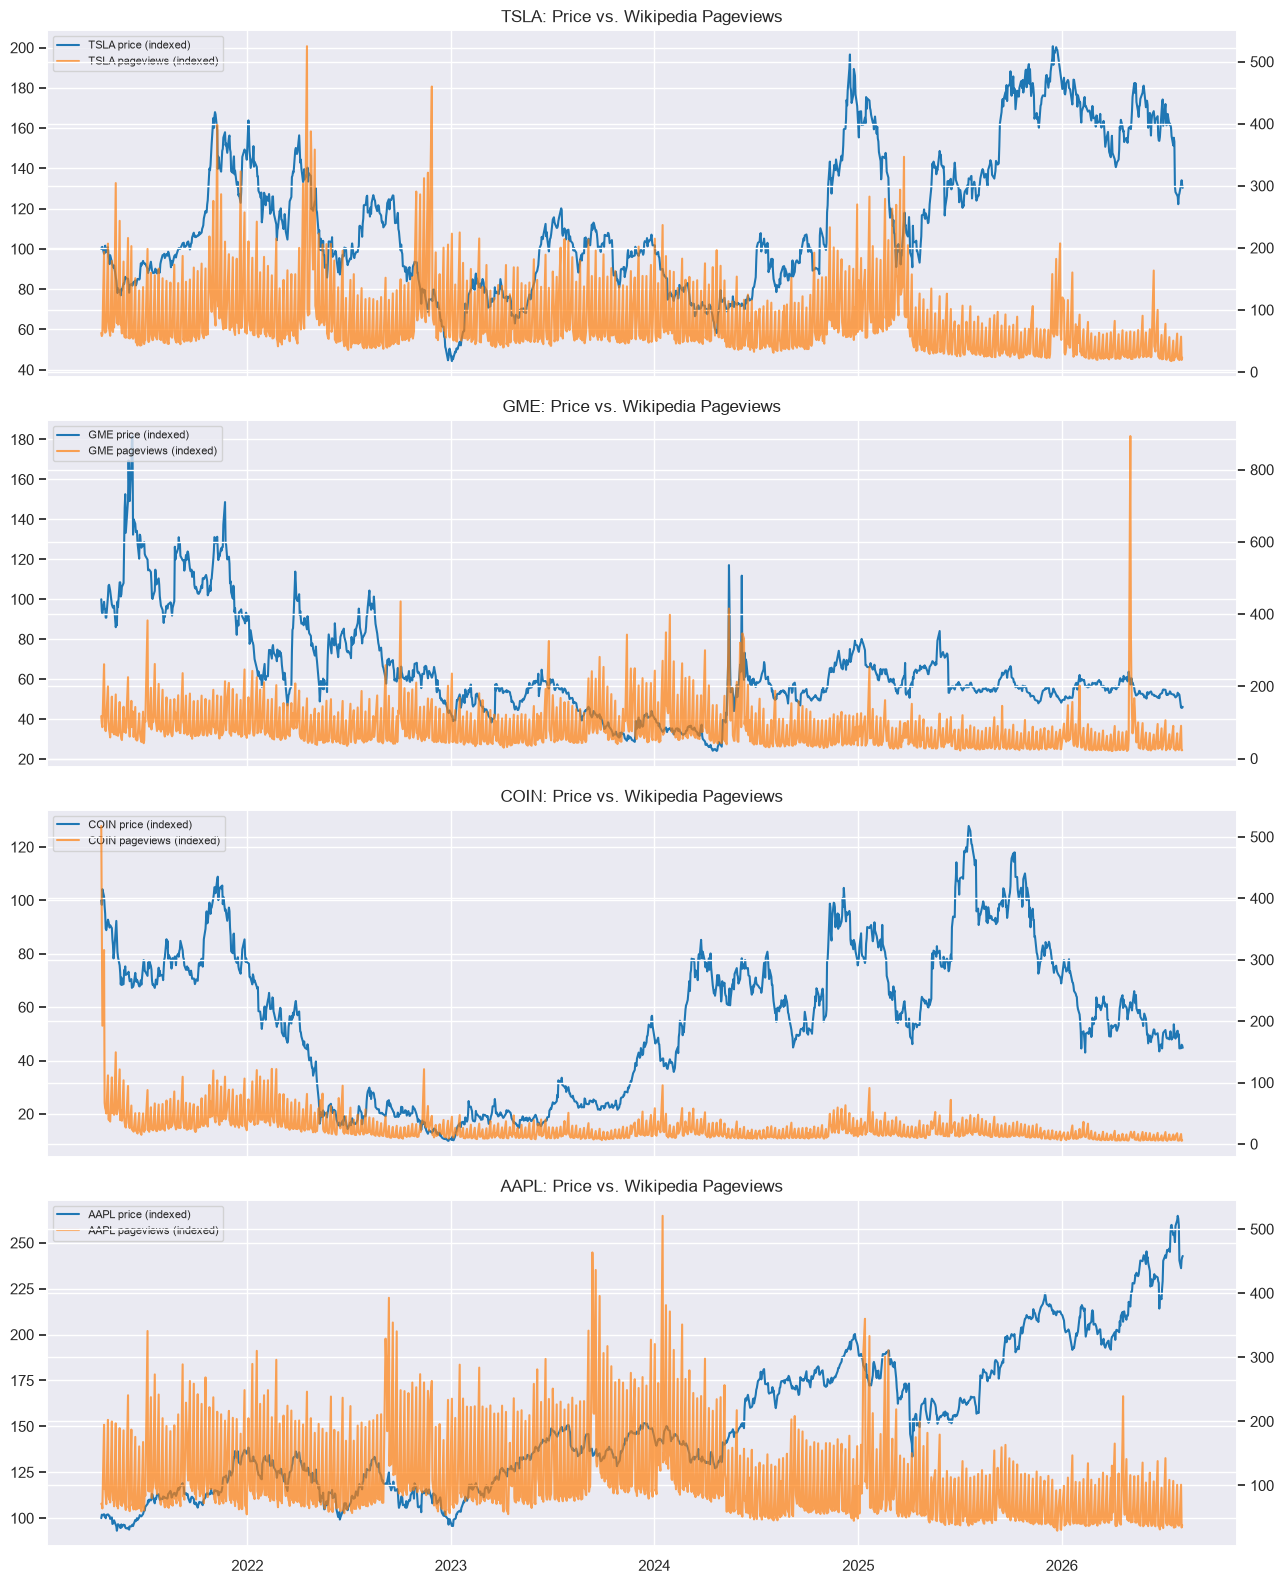

In [5]:
fig, axes = plt.subplots(len(COMPANIES), 1, figsize=(13, 4 * len(COMPANIES)), sharex=True)
for ax, ticker in zip(axes, COMPANIES):
    price = df[f"{ticker}_close"]
    pv = df[f"{ticker}_pv"]
    price_n = price / price.iloc[0] * 100
    pv_n = pv / pv.replace(0, np.nan).iloc[:30].mean() * 100  # index to early baseline, not day 1 (noisy)

    ax.plot(price_n.index, price_n, label=f"{ticker} price (indexed)", color="tab:blue")
    ax2 = ax.twinx()
    ax2.plot(pv_n.index, pv_n, label=f"{ticker} pageviews (indexed)", color="tab:orange", alpha=0.7)
    ax.set_title(f"{ticker}: Price vs. Wikipedia Pageviews")
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


## 4. Returns, Attention Changes & Correlation

We use **pageview growth** (log change), not the raw level, since pageviews have strong trend/base
effects (a company simply gets more Wikipedia traffic over time as it grows) that would otherwise
dominate a naive correlation.


In [6]:
rets = pd.DataFrame(index=df.index)
for ticker in COMPANIES:
    rets[f"{ticker}_ret"] = np.log(df[f"{ticker}_close"]).diff()
    rets[f"{ticker}_pv_chg"] = np.log(df[f"{ticker}_pv"].replace(0, np.nan)).diff()

rets = rets.dropna(how="all")
rets.tail()


,TSLA_ret,TSLA_pv_chg,GME_ret,GME_pv_chg,COIN_ret,COIN_pv_chg,AAPL_ret,AAPL_pv_chg
Date,,,,,,,,
2026-07-31,0.0076,-0.0369,-0.0073,0.1413,-0.1119,0.0206,-0.0764,0.0168
2026-08-03,0.0343,1.0867,-0.1306,1.1899,0.0016,1.0076,-0.0179,0.9806
2026-08-04,0.0162,-1.0747,0.0078,-1.3738,0.0285,-1.1337,0.0195,-1.0770
2026-08-05,-0.0179,0.1700,-0.0105,0.0000,-0.0056,0.1075,0.0052,0.0987
2026-08-06,-0.0104,NaN,0.0107,NaN,-0.0195,NaN,0.0031,NaN


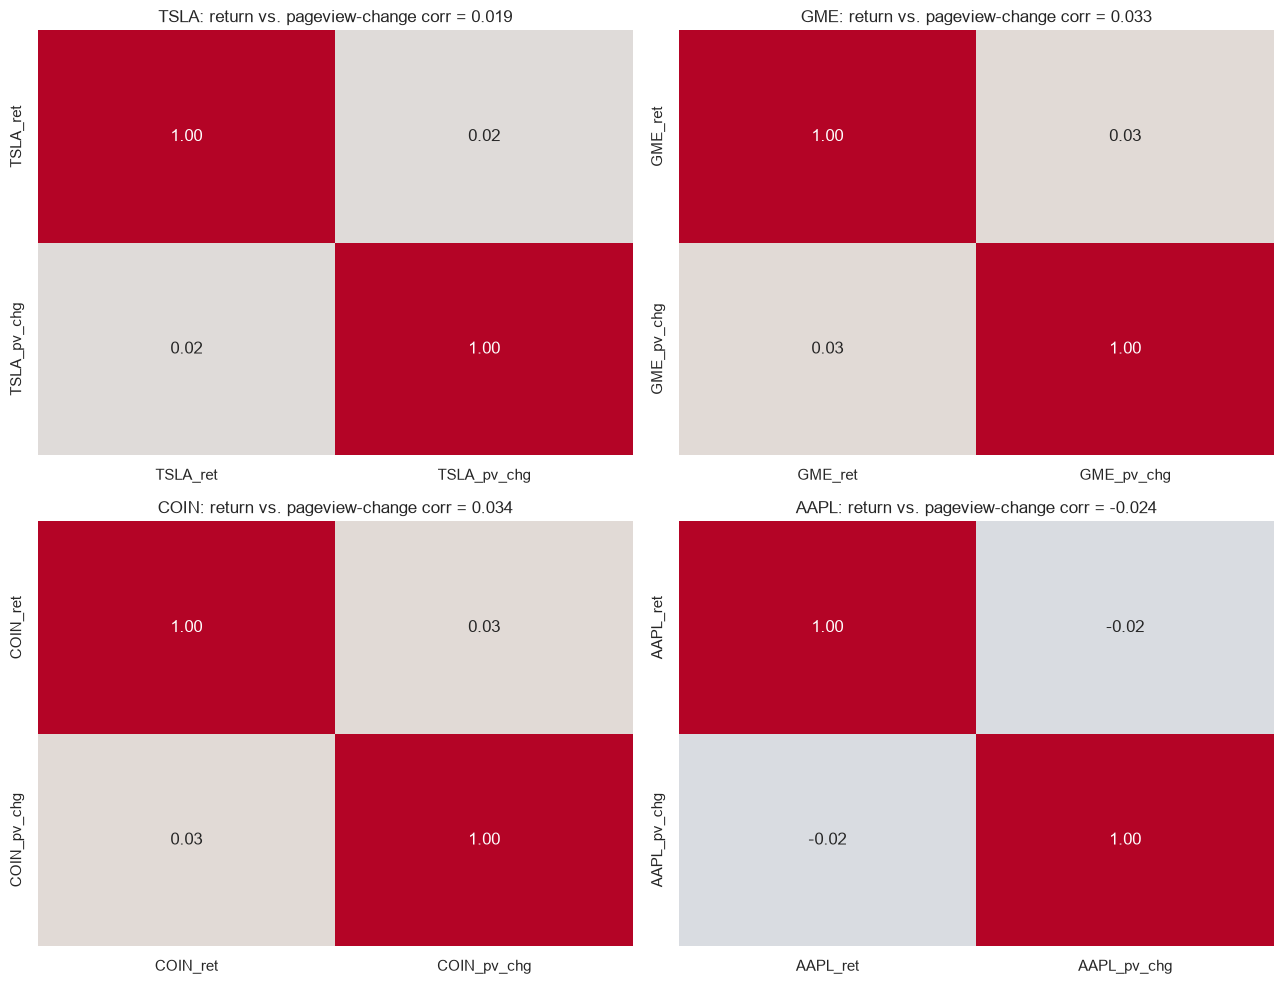

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, ticker in zip(axes.flat, COMPANIES):
    sub = rets[[f"{ticker}_ret", f"{ticker}_pv_chg"]].dropna()
    corr_val = sub.corr().iloc[0, 1]
    sns.heatmap(sub.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"{ticker}: return vs. pageview-change corr = {corr_val:.3f}")
plt.tight_layout()
plt.show()


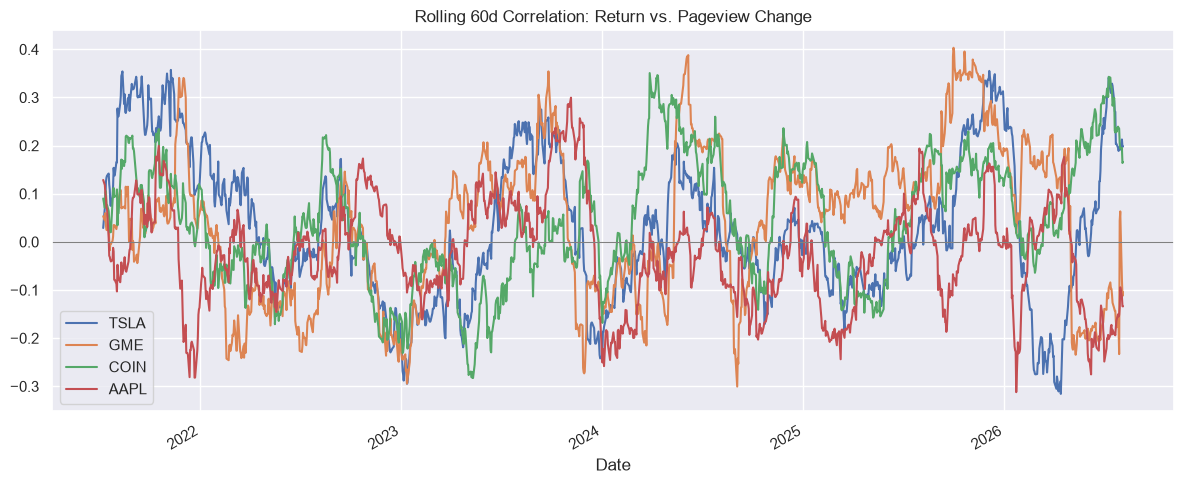

In [8]:
window = 60
fig, ax = plt.subplots()
for ticker in COMPANIES:
    roll = rets[f"{ticker}_ret"].rolling(window).corr(rets[f"{ticker}_pv_chg"])
    roll.plot(ax=ax, label=ticker)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title(f"Rolling {window}d Correlation: Return vs. Pageview Change")
ax.legend()
plt.tight_layout()
plt.show()


## 5. Lead-Lag Analysis (Does Attention Lead Price, or Follow It?)

Two competing stories:
- **Attention leads price**: people research a stock before buying → pageviews rise, then price rises.
- **Price leads attention**: a stock moves on news → people go look up what happened → pageviews rise
  afterward. This is generally the dominant effect in the literature for "look the company up after
  it's in the news," so a strong lag-0 or price-leads-pageviews result would not be surprising.

We test both directions with cross-correlation and Granger causality.


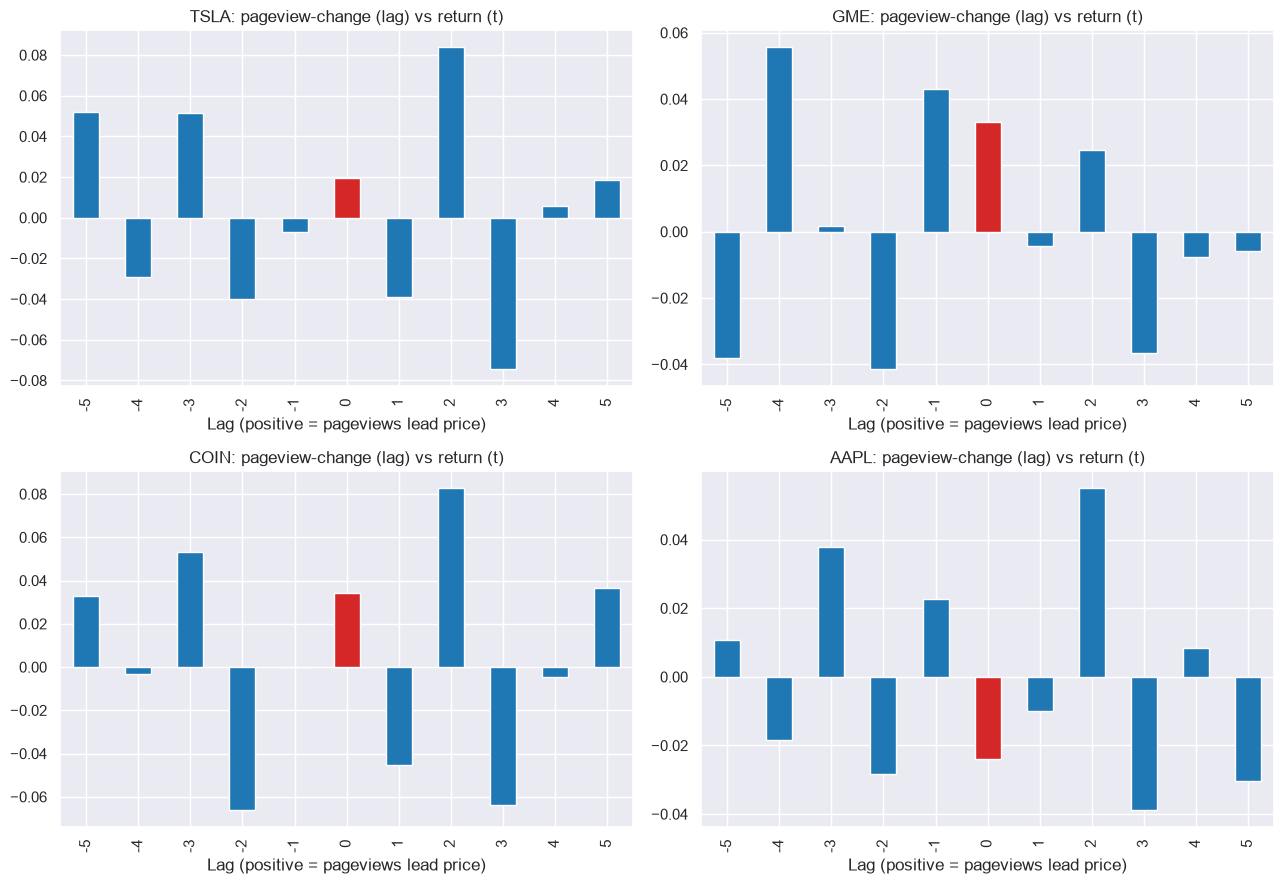

In [9]:
def lagged_corr(y, x, max_lag=5):
    """Positive lag = x's past leads y's present."""
    return pd.Series({lag: y.corr(x.shift(lag)) for lag in range(-max_lag, max_lag + 1)})

max_lag = 5
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, ticker in zip(axes.flat, COMPANIES):
    sub = rets[[f"{ticker}_ret", f"{ticker}_pv_chg"]].dropna()
    ll = lagged_corr(sub[f"{ticker}_ret"], sub[f"{ticker}_pv_chg"], max_lag)
    colors = ["#d62728" if l == 0 else "#1f77b4" for l in ll.index]
    ll.plot(kind="bar", ax=ax, color=colors)
    ax.set_title(f"{ticker}: pageview-change (lag) vs return (t)")
    ax.set_xlabel("Lag (positive = pageviews lead price)")
plt.tight_layout()
plt.show()


In [10]:
from statsmodels.tsa.stattools import grangercausalitytests

for ticker in COMPANIES:
    print(f"\n=== {ticker}: does pageview change Granger-cause return? ===")
    sub = rets[[f"{ticker}_ret", f"{ticker}_pv_chg"]].dropna()
    try:
        grangercausalitytests(sub, maxlag=3, verbose=True)
    except Exception as e:
        print(f"  skipped ({e})")



=== TSLA: does pageview change Granger-cause return? ===

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=1.9961  , p=0.1579  , df_denom=1329, df_num=1
ssr based chi2 test:   chi2=2.0007  , p=0.1572  , df=1
likelihood ratio test: chi2=1.9992  , p=0.1574  , df=1
parameter F test:         F=1.9961  , p=0.1579  , df_denom=1329, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=4.6348  , p=0.0099  , df_denom=1326, df_num=2
ssr based chi2 test:   chi2=9.3045  , p=0.0095  , df=2
likelihood ratio test: chi2=9.2721  , p=0.0097  , df=2
parameter F test:         F=4.6348  , p=0.0099  , df_denom=1326, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=3.7497  , p=0.0107  , df_denom=1323, df_num=3
ssr based chi2 test:   chi2=11.3086 , p=0.0102  , df=3
likelihood ratio test: chi2=11.2608 , p=0.0104  , df=3
parameter F test:         F=3.7497  , p=0.0107  , df_denom=1323, df_num=3

=== GME: does pageview change

## 6. Weekend Attention Buildup vs. Monday Return

Wikipedia gets read on weekends; markets are closed. Does attention that accumulates Friday-through-
Sunday predict Monday's stock move — the same structural idea as the crypto notebook's weekend-gap
test, but here the "24/7 asset" is attention itself, not a tradeable instrument.


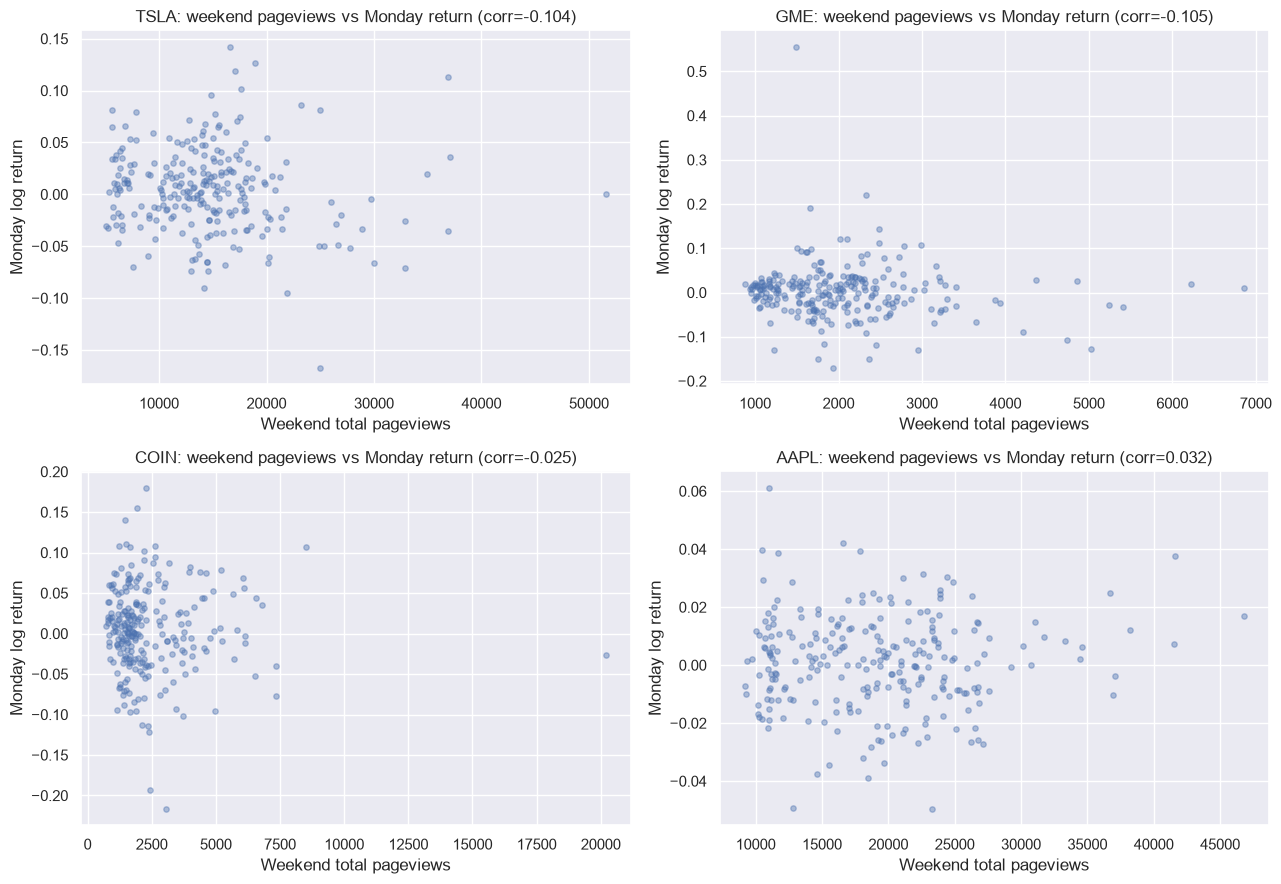

In [11]:
full_pv = full[pv_cols].copy()
full_dow = full_pv.index.dayofweek  # Monday=0

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, ticker in zip(axes.flat, COMPANIES):
    col = f"{ticker}_pv"
    weekend_pv = full_pv.loc[full_dow.isin([5, 6]), col].groupby(
        full_pv.loc[full_dow.isin([5, 6])].index.to_period("W")
    ).sum()
    # Map each weekend's total pageviews to the following Monday's return
    weekend_pv.index = weekend_pv.index.to_timestamp() + pd.Timedelta(days=7)  # approx following Monday
    monday_ret = rets[f"{ticker}_ret"][rets.index.dayofweek == 0]

    merged = pd.DataFrame({"weekend_pv": weekend_pv}).reindex(monday_ret.index).join(monday_ret)
    merged = merged.dropna()
    if len(merged) > 10:
        ax.scatter(merged["weekend_pv"], merged[f"{ticker}_ret"], alpha=0.4, s=15)
        corr_val = merged["weekend_pv"].corr(merged[f"{ticker}_ret"])
        ax.set_title(f"{ticker}: weekend pageviews vs Monday return (corr={corr_val:.3f})")
    else:
        ax.set_title(f"{ticker}: not enough data")
    ax.set_xlabel("Weekend total pageviews")
    ax.set_ylabel("Monday log return")
plt.tight_layout()
plt.show()


## 7. Attention Shock Event Study

Define an "attention shock" day as one where pageview growth's z-score exceeds a threshold, then look
at forward returns/volatility after the shock. GameStop's Jan 2021 squeeze should show up here
dramatically; it's a useful sanity check that the pipeline is capturing real signal, not noise.


In [12]:
def zscore(s, window=60):
    return (s - s.rolling(window).mean()) / s.rolling(window).std()

# z > 3 turned out to be too strict here (0-1 events per company over ~5 years) to say anything
# statistically meaningful; z > 2 gives a usable sample (roughly 9-15 events/company) while still
# selecting genuine outliers rather than routine day-to-day noise (z > 1.5 was too lenient, ~100+
# "events" per company). Tune this if you extend the universe or the time window.
shock_threshold = 2.0
event_results = {}

for ticker in COMPANIES:
    pv_chg = rets[f"{ticker}_pv_chg"]
    z = zscore(pv_chg)
    shock_days = z[z > shock_threshold].index

    fwd_rets = {}
    for h in [1, 3, 5, 10]:
        fwd = np.log(df[f"{ticker}_close"]).diff(h).shift(-h)
        fwd_rets[f"fwd_{h}d_ret"] = fwd.reindex(shock_days)
    event_results[ticker] = pd.DataFrame(fwd_rets)
    print(f"{ticker}: {len(shock_days)} attention-shock days (z > {shock_threshold})")

print()
for ticker, res in event_results.items():
    if len(res) > 0:
        print(f"--- {ticker}: mean forward return after attention shock ---")
        print(res.mean().round(4))
        print()


TSLA: 9 attention-shock days (z > 2.0)
GME: 12 attention-shock days (z > 2.0)
COIN: 15 attention-shock days (z > 2.0)
AAPL: 11 attention-shock days (z > 2.0)

--- TSLA: mean forward return after attention shock ---
fwd_1d_ret    -0.0051
fwd_3d_ret     0.0152
fwd_5d_ret     0.0046
fwd_10d_ret    0.0256
dtype: float64

--- GME: mean forward return after attention shock ---
fwd_1d_ret     0.0256
fwd_3d_ret     0.0429
fwd_5d_ret    -0.0337
fwd_10d_ret   -0.0320
dtype: float64

--- COIN: mean forward return after attention shock ---
fwd_1d_ret    -0.0032
fwd_3d_ret     0.0008
fwd_5d_ret     0.0078
fwd_10d_ret    0.0113
dtype: float64

--- AAPL: mean forward return after attention shock ---
fwd_1d_ret    -0.0058
fwd_3d_ret     0.0004
fwd_5d_ret    -0.0008
fwd_10d_ret   -0.0061
dtype: float64



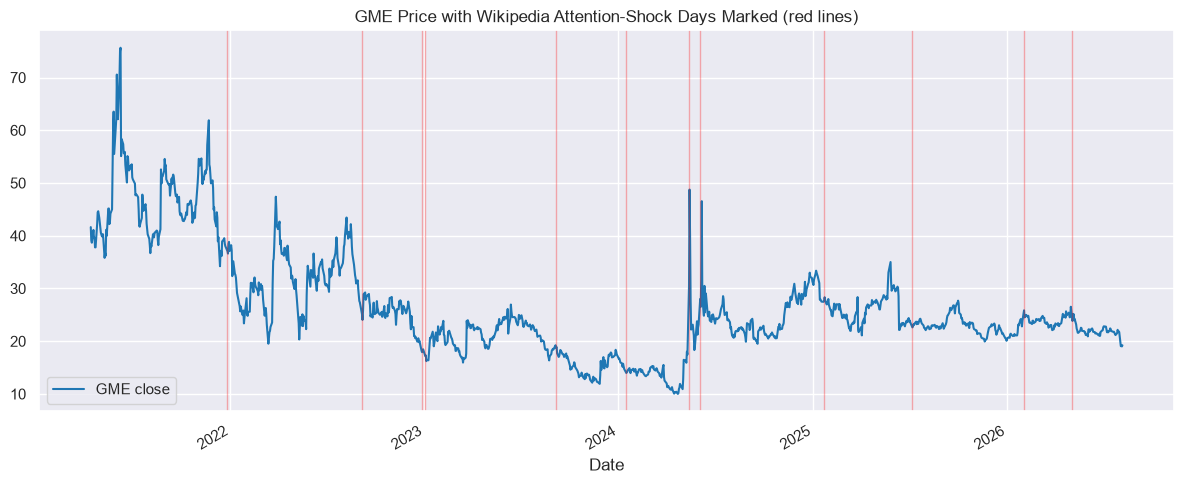

In [13]:
# GameStop close-up: mark attention-shock days on the price chart (Jan 2021 should jump out)
ticker = "GME"
z_gme = zscore(rets[f"{ticker}_pv_chg"])
shock_days_gme = z_gme[z_gme > shock_threshold].index

fig, ax = plt.subplots()
df[f"{ticker}_close"].plot(ax=ax, label="GME close", color="tab:blue")
for d in shock_days_gme:
    if d in df.index:
        ax.axvline(d, color="red", alpha=0.3, linewidth=1)
ax.set_title("GME Price with Wikipedia Attention-Shock Days Marked (red lines)")
ax.legend()
plt.tight_layout()
plt.show()


## 8. Toy Backtest: Fade or Follow the Attention Shock?

Two candidate strategies, tested per company:
1. **Momentum**: go long after an attention shock (attention → more buyers → price continues up).
2. **Reversal**: go short after an attention shock (attention shock = retail FOMO peak → mean-reverts).

No transaction costs modeled — this is a raw-signal check, not a production backtest.


In [14]:
def sharpe(returns, periods_per_year=252):
    r = returns.dropna()
    if len(r) == 0 or r.std() == 0:
        return np.nan
    return (r.mean() / r.std()) * np.sqrt(periods_per_year)

summary_rows = []
for ticker in COMPANIES:
    z = zscore(rets[f"{ticker}_pv_chg"])
    shock = (z > shock_threshold).astype(float)

    momentum_ret = shock.shift(1) * rets[f"{ticker}_ret"]
    reversal_ret = -shock.shift(1) * rets[f"{ticker}_ret"]
    buy_hold = rets[f"{ticker}_ret"]

    summary_rows.append({
        "ticker": ticker,
        "n_shock_days": int(shock.sum()),
        "momentum_sharpe": sharpe(momentum_ret),
        "reversal_sharpe": sharpe(reversal_ret),
        "buy_hold_sharpe": sharpe(buy_hold),
    })

pd.DataFrame(summary_rows).set_index("ticker")


,n_shock_days,momentum_sharpe,reversal_sharpe,buy_hold_sharpe
ticker,,,,
TSLA,9,-0.1257,0.1257,0.0856
GME,12,0.2780,-0.2780,-0.1602
COIN,15,-0.1535,0.1535,-0.1803
AAPL,11,-0.6074,0.6074,0.6082


## 9. Takeaways & Next Steps

- **Compare the four companies**: if GME/TSLA/COIN show meaningfully stronger pageview↔return
  relationships than AAPL, that supports the "retail attention matters more for retail-driven names"
  hypothesis — worth extending to a larger cross-section (e.g. all Russell 2000 vs S&P 100) to see if
  it holds systematically rather than in this small, hand-picked sample.
- **Check direction carefully**: if the lead-lag/Granger results say price leads pageviews (not the
  reverse), that's still useful — it means pageviews are a *confirmation* signal (news already moved
  the stock, and elevated search interest tells you the move is "real"/getting attention), not a
  standalone leading indicator.
- **Event study robustness**: GME's Jan 2021 episode is a single extreme event that can dominate
  average statistics — rerun the event study excluding it to check whether the effect generalizes or
  is entirely driven by one squeeze.
- **Extend the dataset**: Wikimedia also exposes per-country and per-referrer breakdowns, and Google
  Trends is a comparable (if noisier, normalized 0-100) alternative attention proxy worth
  cross-validating against.
- **Robustness**: as with the companion notebook, re-run with out-of-sample splits and transaction-
  cost-adjusted backtests before treating any of this as an actual edge.
